In [73]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Configure matplotlib formatting for professional thesis documentation
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

print("Phase 0: Research environment and tracking metrics initialized.")


Phase 0: Research environment and tracking metrics initialized.


In [74]:
# Define local path configuration for the raw laboratory reflectance dataset
DATA_PATH_RAW = 'data/__Mean_Spectra_Reflectance.csv'

if not os.path.exists(DATA_PATH_RAW):
    raise FileNotFoundError(f"Missing file at {DATA_PATH_RAW}. Check local file tree structure.")

# Ingest dataset
df_raw = pd.read_csv(DATA_PATH_RAW)
wavelength_features = df_raw['wavelength'].values.astype(str)

# Extract column IDs excluding index column and execute structural transposition
sample_cols = [col for col in df_raw.columns if col != 'wavelength']
transposed_raw = df_raw[sample_cols].T
transposed_raw.columns = wavelength_features
transposed_raw = transposed_raw.reset_index().rename(columns={'index': 'sample_id'})

# Define parsing rules to tag binary target classifications (PLA vs PET)
def parse_polymer_type(sample_id):
    if '_PLA_' in sample_id:
        return 'PLA'
    elif '_PET_' in sample_id:
        return 'PET'
    return None

# Generate ground-truth labels for the machine learning pipeline
transposed_raw['target_label'] = transposed_raw['sample_id'].apply(parse_polymer_type)
labeled_raw_df = transposed_raw[transposed_raw['target_label'].notna()].copy()

print(f"Phase 1: Raw dataset loaded. Initial structural shape: {labeled_raw_df.shape}")


Phase 1: Raw dataset loaded. Initial structural shape: (74, 1553)


In [75]:
print("============================================================")
print("             DATASET STRUCTURAL PREVIEW & DESCRIPTION       ")
print("============================================================")
print(f"Total Evaluated Sample Mixtures (Rows) : {labeled_raw_df.shape[0]}")
print(f"Total Spectral Wavelength Bands (Cols) : {len(wavelength_features)} features")
print("\nFirst 5 rows of the processed raw training matrix:")
display(labeled_raw_df.head(5))


             DATASET STRUCTURAL PREVIEW & DESCRIPTION       
Total Evaluated Sample Mixtures (Rows) : 74
Total Spectral Wavelength Bands (Cols) : 1551 features

First 5 rows of the processed raw training matrix:


,sample_id,850.0,851.0,852.0,853.0,854.0,855.0,856.0,857.0,858.0,...,2392.0,2393.0,2394.0,2395.0,2396.0,2397.0,2398.0,2399.0,2400.0,target_label
6,Bu5_PET_0X15,0.984852,0.983838,0.982838,0.981858,0.980902,0.979975,0.979081,0.978223,0.977405,...,0.915427,0.920502,0.926859,0.934626,0.943942,0.954960,0.967848,0.982792,1.000000,PET
7,Bu5_PET_0X5,0.975726,0.975063,0.974347,0.973591,0.972807,0.972006,0.971197,0.970391,0.969597,...,0.884558,0.890238,0.897840,0.907611,0.919825,0.934793,0.952866,0.974447,1.000000,PET
8,Bu5_PET_1X5,0.999081,0.998541,0.998058,0.997629,0.997250,0.996916,0.996623,0.996367,0.996145,...,0.915657,0.918024,0.922073,0.928059,0.936264,0.947001,0.960624,0.977533,0.998187,PET
9,Bu5_PET_5,0.996848,0.996582,0.996322,0.996068,0.995821,0.995583,0.995353,0.995134,0.994924,...,0.916633,0.918132,0.921383,0.926678,0.934337,0.944718,0.958222,0.975308,0.996504,PET
10,Bu5_PET_15,1.000000,0.995693,0.991937,0.988686,0.985899,0.983537,0.981563,0.979941,0.978638,...,0.817874,0.824334,0.832861,0.843948,0.858151,0.876103,0.898544,0.926340,0.960528,PET


     VISUAL ANALYSIS: LABORATORY FULL-RANGE REFERENCE SPECTRA 


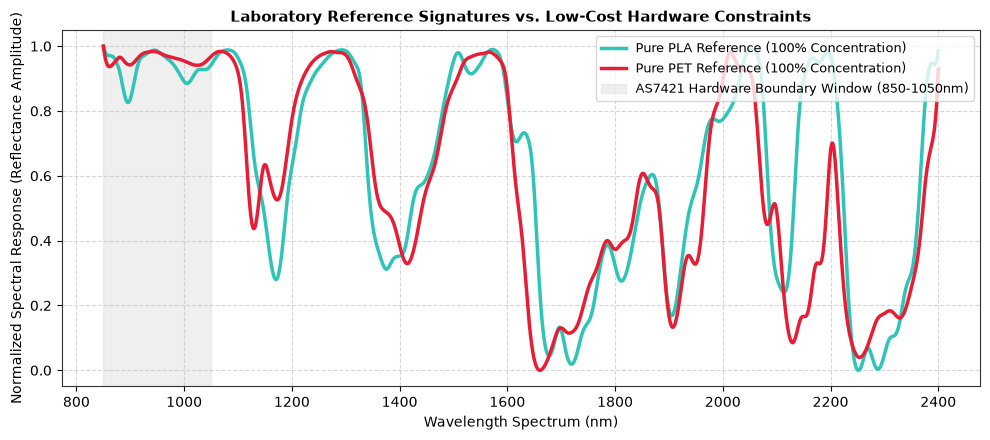

In [76]:
print("============================================================")
print("     VISUAL ANALYSIS: LABORATORY FULL-RANGE REFERENCE SPECTRA ")
print("============================================================")

# Isolate pure 100% reference signatures from matrix rows
pure_pla_cols = [col for col in transposed_raw['sample_id'] if '_PLA_100' in col]
pure_pet_cols = [col for col in transposed_raw['sample_id'] if '_PET_100' in col]
float_wavelengths = wavelength_features.astype(float)

plt.figure(figsize=(10, 4.5))
if pure_pla_cols and pure_pet_cols:
    plt.plot(float_wavelengths, transposed_raw[transposed_raw['sample_id'].isin(pure_pla_cols)][wavelength_features].mean(axis=0), 
             label='Pure PLA Reference (100% Concentration)', color='#2ec4b6', linewidth=2.5)
    plt.plot(float_wavelengths, transposed_raw[transposed_raw['sample_id'].isin(pure_pet_cols)][wavelength_features].mean(axis=0), 
             label='Pure PET Reference (100% Concentration)', color='#e71d36', linewidth=2.5)

# Demarcate low-cost hardware sensor restriction zone (850-1050nm)
plt.axvspan(850, 1050, color='#cccccc', alpha=0.3, label='AS7421 Hardware Boundary Window (850-1050nm)')

plt.title('Laboratory Reference Signatures vs. Low-Cost Hardware Constraints', fontsize=11, fontweight='bold')
plt.xlabel('Wavelength Spectrum (nm)', fontsize=10)
plt.ylabel('Normalized Spectral Response (Reflectance Amplitude)', fontsize=10)
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Experimental Baseline Evaluation Complete:
  - Initial Unfiltered Hardware Classification Accuracy = 56.52%


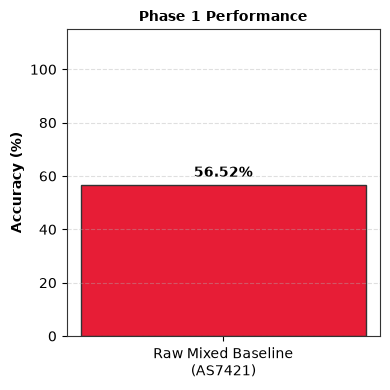

In [77]:
# Slicing the feature vector space to match hardware physical limit specifications
numeric_wavelengths = wavelength_features.astype(float)
as7421_channels = [str(w) for w in numeric_wavelengths if 850.0 <= w <= 1050.0]

X_raw = labeled_raw_df[as7421_channels].values
y_raw = labeled_raw_df['target_label'].values

# Split data using a stratified training/testing partition
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_raw, y_raw, test_size=0.3, random_state=42, stratify=y_raw
)

# Fit baseline classifier engine
model_raw = RandomForestClassifier(n_estimators=100, random_state=42)
model_raw.fit(X_train_r, y_train_r)
acc_raw = accuracy_score(y_test_r, model_raw.predict(X_test_r)) * 100

print(f"Experimental Baseline Evaluation Complete:")
print(f"  - Initial Unfiltered Hardware Classification Accuracy = {acc_raw:.2f}%")

# Instant performance visualization
plt.figure(figsize=(4, 4))
bar = plt.bar(['Raw Mixed Baseline\n(AS7421)'], [acc_raw], color='#e71d36', width=0.4, edgecolor='#333333')
plt.ylabel('Accuracy (%)', fontweight='semibold')
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.text(bar[0].get_x() + bar[0].get_width()/2., acc_raw + 2, f'{acc_raw:.2f}%', ha='center', va='bottom', fontweight='bold')
plt.title('Phase 1 Performance', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


Operational Pipeline Optimization Complete:
  - Filtered Macro-Waste Classification Accuracy = 75.00%


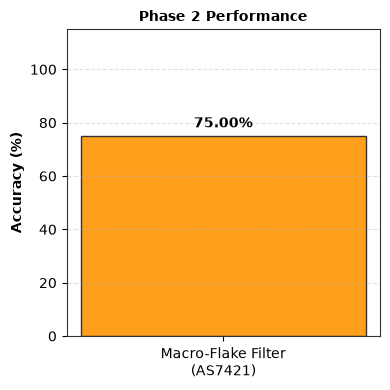

In [78]:
# Define filter logic to isolate macroscopic recycling waste configurations
def filter_macroscopic_waste(sample_id):
    if any(sample_id.endswith(suffix) for suffix in ['_15', '_50', '_100']):
        if '_PLA_' in sample_id: return 'PLA'
        elif '_PET_' in sample_id: return 'PET'
    return None

# Generate the operationally filtered database matrix copy
operational_df = transposed_raw.copy()
operational_df['target_label'] = operational_df['sample_id'].apply(filter_macroscopic_waste)
operational_df = operational_df[operational_df['target_label'].notna()]

X_op = operational_df[as7421_channels].values
y_op = operational_df['target_label'].values

# Train-Test Split on isolated operational data
X_train_o, X_test_o, y_train_o, y_test_o = train_test_split(
    X_op, y_op, test_size=0.3, random_state=42, stratify=y_op
)

model_op = RandomForestClassifier(n_estimators=100, random_state=42)
model_op.fit(X_train_o, y_train_o)
acc_operational = accuracy_score(y_test_o, model_op.predict(X_test_o)) * 100

print(f"Operational Pipeline Optimization Complete:")
print(f"  - Filtered Macro-Waste Classification Accuracy = {acc_operational:.2f}%")

# Instant performance visualization
plt.figure(figsize=(4, 4))
bar = plt.bar(['Macro-Flake Filter\n(AS7421)'], [acc_operational], color='#ff9f1c', width=0.4, edgecolor='#333333')
plt.ylabel('Accuracy (%)', fontweight='semibold')
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.text(bar[0].get_x() + bar[0].get_width()/2., acc_operational + 2, f'{acc_operational:.2f}%', ha='center', va='bottom', fontweight='bold')
plt.title('Phase 2 Performance', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


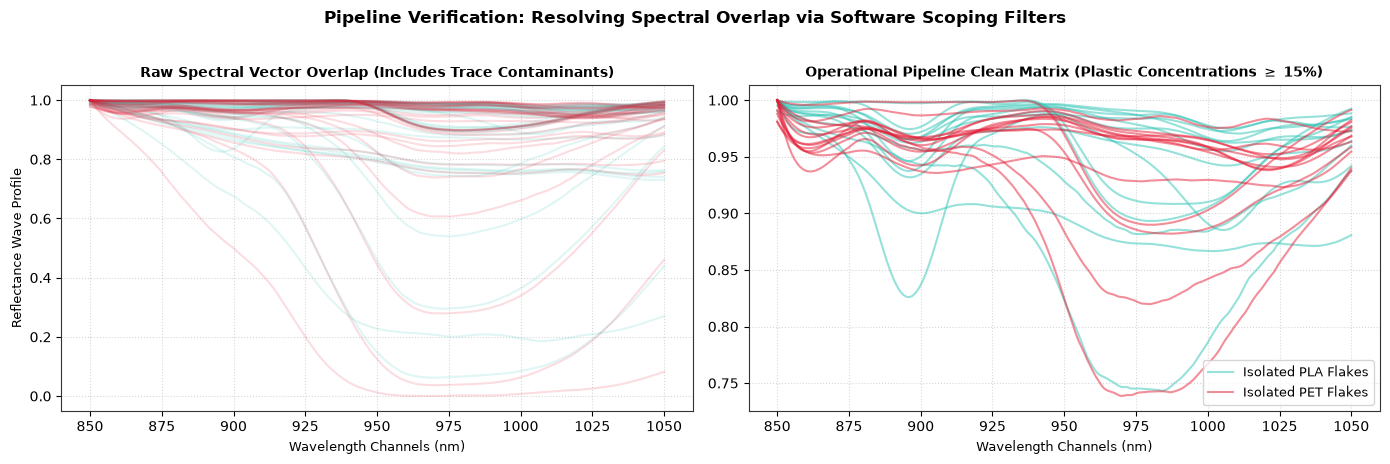

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
as7421_float = np.array(as7421_channels).astype(float)

# Plot Subpanel A: Raw un-optimized mixture vector overlap
axes[0].plot(as7421_float, labeled_raw_df[labeled_raw_df['target_label']=='PLA'][as7421_channels].T, color='#2ec4b6', alpha=0.15)
axes[0].plot(as7421_float, labeled_raw_df[labeled_raw_df['target_label']=='PET'][as7421_channels].T, color='#e71d36', alpha=0.15)
axes[0].set_title('Raw Spectral Vector Overlap (Includes Trace Contaminants)', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Wavelength Channels (nm)', fontsize=9)
axes[0].set_ylabel('Reflectance Wave Profile', fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.5)

# Plot Subpanel B: Algorithmic extraction cleanup via software filtering
axes[1].plot(as7421_float, operational_df[operational_df['target_label']=='PLA'][as7421_channels].T, color='#2ec4b6', alpha=0.5, label='Isolated PLA Flakes')
axes[1].plot(as7421_float, operational_df[operational_df['target_label']=='PET'][as7421_channels].T, color='#e71d36', alpha=0.5, label='Isolated PET Flakes')
axes[1].set_title(r'Operational Pipeline Clean Matrix (Plastic Concentrations $\geq$ 15%)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Wavelength Channels (nm)', fontsize=9)

# Erase structural repetition inside legends using a single handle mapper dictionary
handles, labels = axes[1].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axes[1].legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Pipeline Verification: Resolving Spectral Overlap via Software Scoping Filters', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


     RAW INTENSITY HARDWARE CEILING COMPARISON ANALYSIS     
  - AS7265x Operating Window (850 - 940 nm)   : 75.00% accuracy
  - AS7421 Operating Window  (850 - 1050 nm)  : 75.00% accuracy


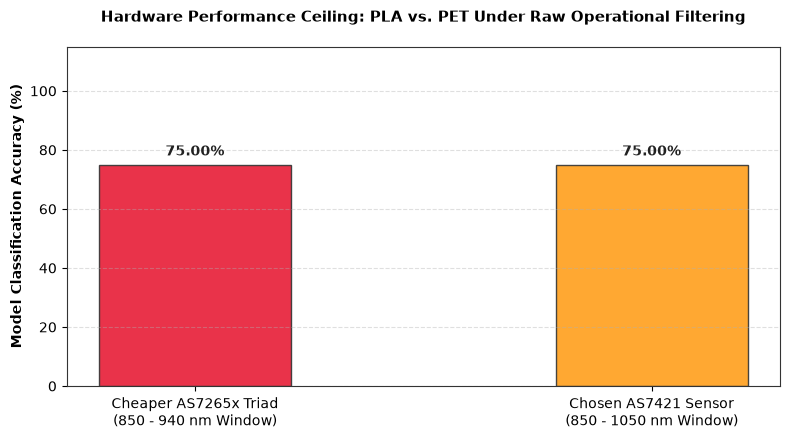

In [80]:
# Segment the narrower sub-window corresponding to the cheaper sensor triad
as7265x_channels = [str(w) for w in numeric_wavelengths if 850.0 <= w <= 940.0]

X_cheap_op = operational_df[as7265x_channels].values
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cheap_op, y_op, test_size=0.3, random_state=42, stratify=y_op
)

model_cheap_op = RandomForestClassifier(n_estimators=100, random_state=42)
model_cheap_op.fit(X_train_c, y_train_c)
acc_cheap_op = accuracy_score(y_test_c, model_cheap_op.predict(X_test_c)) * 100

print("============================================================")
print("     RAW INTENSITY HARDWARE CEILING COMPARISON ANALYSIS     ")
print("============================================================")
print(f"  - AS7265x Operating Window (850 - 940 nm)   : {acc_cheap_op:.2f}% accuracy")
print(f"  - AS7421 Operating Window  (850 - 1050 nm)  : {acc_operational:.2f}% accuracy")

# Render the Hardware ceiling side-by-side bar chart
hardware_sensors = ['Cheaper AS7265x Triad\n(850 - 940 nm Window)', 'Chosen AS7421 Sensor\n(850 - 1050 nm Window)']
hardware_scores = [acc_cheap_op, acc_operational]

plt.figure(figsize=(8, 4.5))
hardware_bars = plt.bar(hardware_sensors, hardware_scores, color=['#e71d36', '#ff9f1c'], width=0.42, edgecolor='#333333', alpha=0.9)
plt.title('Hardware Performance Ceiling: PLA vs. PET Under Raw Operational Filtering', fontsize=11, fontweight='bold', pad=18)
plt.ylabel('Model Classification Accuracy (%)', fontsize=10, fontweight='semibold')
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.4)

for bar in hardware_bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2, f'{height:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#222222')

plt.tight_layout()
plt.show()


       FULL MULTI-SENSOR SPECTRUM COMPARISON LOOP            


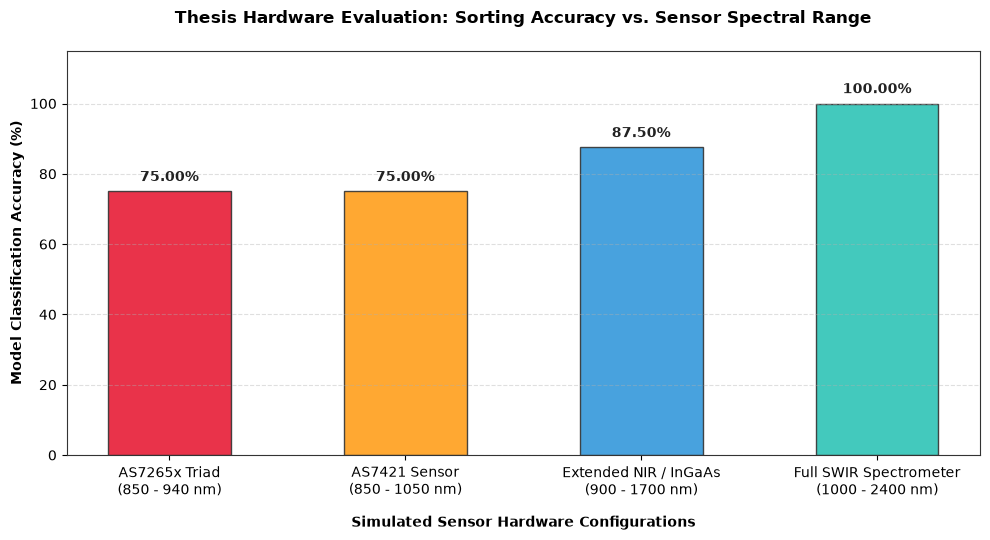

In [81]:
print("============================================================")
print("       FULL MULTI-SENSOR SPECTRUM COMPARISON LOOP            ")
print("============================================================")

sensor_profiles = {
    'AS7265x Triad\n(850 - 940 nm)': {'min_w': 850.0, 'max_w': 940.0, 'color': '#e71d36'},
    'AS7421 Sensor\n(850 - 1050 nm)': {'min_w': 850.0, 'max_w': 1050.0, 'color': '#ff9f1c'},
    'Extended NIR / InGaAs\n(900 - 1700 nm)': {'min_w': 900.0, 'max_w': 1700.0, 'color': '#3498db'},
    'Full SWIR Spectrometer\n(1000 - 2400 nm)': {'min_w': 1000.0, 'max_w': 2400.0, 'color': '#2ec4b6'}
}

sensor_names = []
sensor_accuracies = []
sensor_colors = []

for name, config in sensor_profiles.items():
    active_channels = [str(w) for w in numeric_wavelengths if config['min_w'] <= w <= config['max_w']]
    if len(active_channels) == 0: continue
        
    X_sim = operational_df[active_channels].values
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_sim, y_op, test_size=0.3, random_state=42, stratify=y_op
    )
    
    model_sim = RandomForestClassifier(n_estimators=100, random_state=42)
    model_sim.fit(X_train_s, y_train_s)
    acc_sim = accuracy_score(y_test_s, model_sim.predict(X_test_s)) * 100
    
    sensor_names.append(name)
    sensor_accuracies.append(acc_sim)
    sensor_colors.append(config['color'])

# Render the multi-sensor scaling chart
plt.figure(figsize=(10, 5.5))
swir_bars = plt.bar(sensor_names, sensor_accuracies, color=sensor_colors, width=0.52, edgecolor='#333333', alpha=0.9)
plt.title('Thesis Hardware Evaluation: Sorting Accuracy vs. Sensor Spectral Range', fontsize=12, fontweight='bold', pad=20)
plt.ylabel('Model Classification Accuracy (%)', fontsize=10, fontweight='semibold')
plt.xlabel('Simulated Sensor Hardware Configurations', fontsize=10, fontweight='semibold', labelpad=12)
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.4)

for bar in swir_bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2, f'{height:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#222222')

plt.tight_layout()
plt.show()


     FIRST DERIVATIVE MATHEMATICAL CEILING RESCUE           
  - AS7265x Range Derivative Accuracy : 87.50%
  - AS7421 Range Derivative Accuracy  : 87.50%


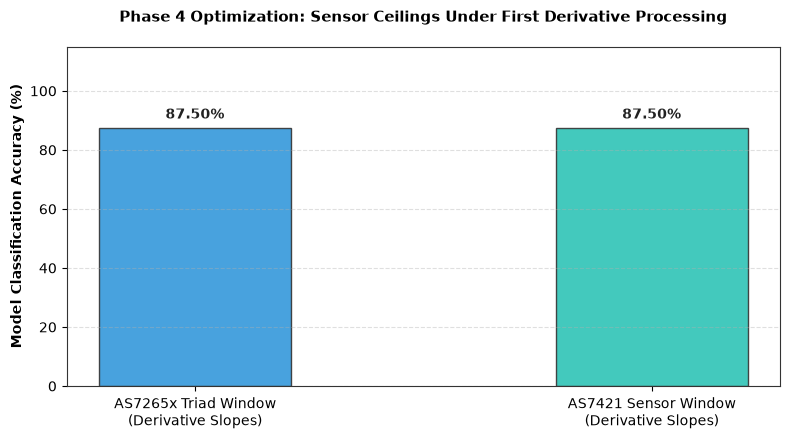

In [82]:
# Define local path configuration for the advanced first-derivative table
DATA_PATH_DER = 'data/__Mean_Spectra_Absorption_der1.csv'

if not os.path.exists(DATA_PATH_DER):
    raise FileNotFoundError(f"Missing file at {DATA_PATH_DER}. Check local file tree structure.")

# Load and transpose derivative matrix configurations
df_der = pd.read_csv(DATA_PATH_DER)
transposed_der = df_der[sample_cols].T
transposed_der.columns = wavelength_features
transposed_der = transposed_der.reset_index().rename(columns={'index': 'sample_id'})

# Apply operational macro-waste filter matrix tags
transposed_der['target_label'] = transposed_der['sample_id'].apply(filter_macroscopic_waste)
operational_der_df = transposed_der[transposed_der['target_label'].notna()]

y_der = operational_der_df['target_label'].values

# Run final first derivative model evaluations for both channels back-to-back
X_as7265x_der = operational_der_df[as7265x_channels].values
X_train_d72, X_test_d72, y_train_d72, y_test_d72 = train_test_split(X_as7265x_der, y_der, test_size=0.3, random_state=42, stratify=y_der)
model_d72 = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train_d72, y_train_d72)
acc_final_7265 = accuracy_score(y_test_d72, model_d72.predict(X_test_d72)) * 100

X_as7421_der = operational_der_df[as7421_channels].values
X_train_d74, X_test_d74, y_train_d74, y_test_d74 = train_test_split(X_as7421_der, y_der, test_size=0.3, random_state=42, stratify=y_der)
model_d74 = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train_d74, y_train_d74)
acc_final_7421 = accuracy_score(y_test_d74, model_d74.predict(X_test_d74)) * 100

print("============================================================")
print("     FIRST DERIVATIVE MATHEMATICAL CEILING RESCUE           ")
print("============================================================")
print(f"  - AS7265x Range Derivative Accuracy : {acc_final_7265:.2f}%")
print(f"  - AS7421 Range Derivative Accuracy  : {acc_final_7421:.2f}%")

# Plot Phase 4 Derivative Comparison Graph
der_sensors = ['AS7265x Triad Window\n(Derivative Slopes)', 'AS7421 Sensor Window\n(Derivative Slopes)']
der_scores = [acc_final_7265, acc_final_7421]

plt.figure(figsize=(8, 4.5))
der_bars = plt.bar(der_sensors, der_scores, color=['#3498db', '#2ec4b6'], width=0.42, edgecolor='#333333', alpha=0.9)
plt.title('Phase 4 Optimization: Sensor Ceilings Under First Derivative Processing', fontsize=11, fontweight='bold', pad=18)
plt.ylabel('Model Classification Accuracy (%)', fontsize=10, fontweight='semibold')
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.4)

for bar in der_bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2, f'{height:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#222222')

plt.tight_layout()
plt.show()


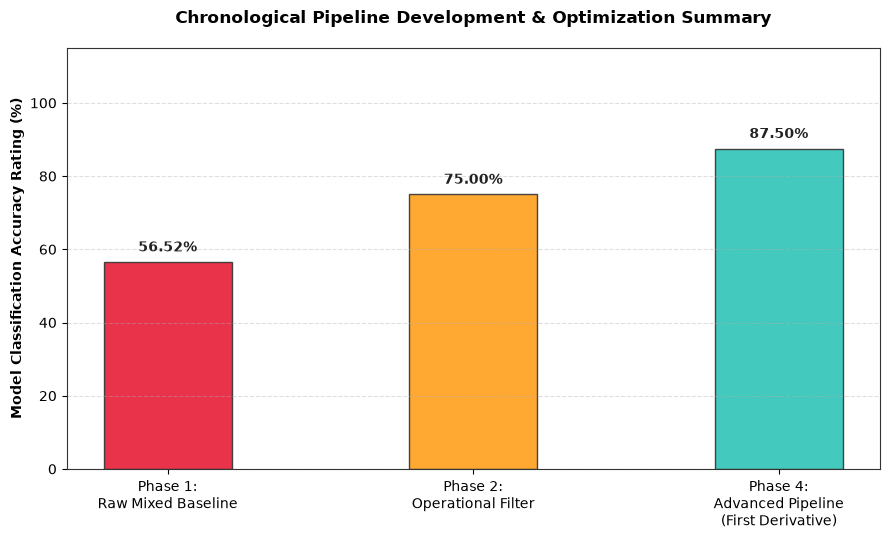

In [83]:
stages = ['Phase 1:\nRaw Mixed Baseline', 'Phase 2:\nOperational Filter', 'Phase 4:\nAdvanced Pipeline\n(First Derivative)']
metrics = [acc_raw, acc_operational, acc_final_7421]

plt.figure(figsize=(9, 5.5))
summary_bars = plt.bar(stages, metrics, color=['#e71d36', '#ff9f1c', '#2ec4b6'], width=0.42, edgecolor='#333333', alpha=0.9)
plt.title('Chronological Pipeline Development & Optimization Summary', fontsize=12, fontweight='bold', pad=18)
plt.ylabel('Model Classification Accuracy Rating (%)', fontsize=10, fontweight='semibold')
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.4)

for bar in summary_bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2, f'{height:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#222222')

plt.tight_layout()
plt.show()
